In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import import_ipynb 
import funzionic

# ==========================================
# 1. DEFINIZIONE STRATEGIE E MATRICE GUADAGNI
# ==========================================
# Impostazione dei parametri (adattabili per qualsiasi configurazione del gioco)
n = 5  # Soldati del giocatore 1
m = 4  # Soldati del giocatore 2
l = 3  # Numero di zone del gioco

# Generazione delle strategie per entrambi i giocatori
strategie_giocatore_1 = list(funzionic.genera_strategie(n, l))
strategie_giocatore_2 = list(funzionic.genera_strategie(m, l))

# Creazione del dizionario delle classi e della lista dei nomi
classi_giocatore_2 = funzionic.raggruppa_in_classi(strategie_giocatore_2)
nomi_classi = list(classi_giocatore_2.keys())

# Volendo si può fare la stessa cosa anche per le classi del giocatore 1
# classi_giocatore_1 = raggruppa_in_classi(strategie_giocatore_1)
lunghezza1 = len(strategie_giocatore_1)
lunghezza2 = len(strategie_giocatore_2)
#A = np.zeros((lunghezza1, lunghezza2))
#for i, s1 in enumerate(strategie_giocatore_1):
#    for j, s2 in enumerate(strategie_giocatore_2):
#        p1 = sum([1 + s2[k] if s1[k] > s2[k] else 0 for k in range(l)])
#        p2 = sum([1 + s1[k] if s2[k] > s1[k] else 0 for k in range(l)])
#        A[i, j] = p1 - p2 
# --- INCOLLA QUESTO AL LORO POSTO ---
S1 = np.array(strategie_giocatore_1)
S2 = np.array(strategie_giocatore_2)

# Vettorializzazione del confronto tra tutte le strategie
win1 = S1[:, None, :] > S2[None, :, :]
win2 = S2[None, :, :] > S1[:, None, :]

# Calcolo istantaneo dei punteggi
p1_matrix = np.sum(win1 * (1 + S2[None, :, :]), axis=2)
p2_matrix = np.sum(win2 * (1 + S1[:, None, :]), axis=2)

A = p1_matrix - p2_matrix

In [2]:
# ==========================================
# 2. CALCOLO DELLE DISTANZE STRATEGICHE E FISICHE
# ==========================================
D_strat_norm, D_fisica_norm = funzionic.calcola_distanze(A, strategie_giocatore_2, lunghezza2)

In [3]:
# ==========================================
# 3. GENERAZIONE STORICO (giocatore umano)
# ==========================================
# Usa solo variabili già presenti: A, S2, m, lunghezza1, lunghezza2, strategie_giocatore_2
storico = funzionic.carica_storico_da_csv(
    'blotto_1791232163824.csv',
    strategie_giocatore_2
)
print(f"Round caricati: {len(storico)}")
storico = storico[1:40]

Round caricati: 39


In [4]:
# ==========================================
# 4. INFERENZA PARALLELA (I 3 MODELLI)
# ==========================================

alpha = np.ones(lunghezza2) 
somma_alpha = np.sum(alpha)

# --- MODELLO 1: DIRICHLET STANDARD ---
storico = np.array(storico)
conteggi_reali = np.bincount(storico, minlength=lunghezza2)
prob_dirichlet = funzionic.probabilita_dirichlet(conteggi_reali, storico)

# --- MODELLO 2: KERNEL FISSO ---
theta_fisso = 0.15
sigma_fisso = 0.2
D_ibrida_fissa = (1 - theta_fisso) * D_strat_norm + theta_fisso * D_fisica_norm
K_fisso = np.exp(- (D_ibrida_fissa**2) / (2 * sigma_fisso**2))
K_fisso_norm = K_fisso / K_fisso.sum(axis=1, keepdims=True)
spillover_fisso = np.sum(K_fisso_norm[storico], axis=0)
prob_kernel_fisso = (spillover_fisso + alpha) / (np.sum(spillover_fisso) + somma_alpha)

# --- MODELLO 3: KERNEL CV (OTTIMIZZAZIONE 2D) ---
theta_opt, sigma_opt = funzionic.cross_validation_2d(
    storico, D_strat_norm, D_fisica_norm, 
    [0.05, 0.15, 0.35, 0.50, 0.65, 0.85, 0.95], 
    [0.001, 0.01, 0.025, 0.05, 0.10, 0.20, 0.60], alpha, somma_alpha)

D_ibrida_opt = (1 - theta_opt) * D_strat_norm + theta_opt * D_fisica_norm
K_opt = np.exp(- (D_ibrida_opt**2) / (2 * sigma_opt**2))
K_opt_norm = K_opt / K_opt.sum(axis=1, keepdims=True)
spillover_opt = np.sum(K_opt_norm[storico], axis=0)
prob_kernel_opt = (spillover_opt + alpha) / (np.sum(spillover_opt) + somma_alpha)

In [5]:
# ==========================================
# 5. AGGREGAZIONE E VISUALIZZAZIONE
# ==========================================


prob_classi_dirichlet = funzionic.aggrega_per_classi(prob_dirichlet, nomi_classi, classi_giocatore_2, strategie_giocatore_2)
prob_classi_fisso = funzionic.aggrega_per_classi(prob_kernel_fisso, nomi_classi, classi_giocatore_2, strategie_giocatore_2)
prob_classi_opt = funzionic.aggrega_per_classi(prob_kernel_opt, nomi_classi, classi_giocatore_2, strategie_giocatore_2)

n_classi = len(nomi_classi)


print("=== STIMA PROBABILITÀ STRATEGIE PURE ===")
print(f"Configurazione: n={n}, m={m}, l={l}")
print(f"Round totali analizzati: {len(storico)}")
print(f"Kernel Fisso: θ={theta_fisso}, σ={sigma_fisso}")
print(f"Kernel CV Ottimizzato: θ={theta_opt}, σ={sigma_opt}\n")

# ==========================================
# TABELLA 1: STRATEGIE PURE
# ==========================================
etichette_strat = [f"Strat {i+1} {mossa}" for i, mossa in enumerate(strategie_giocatore_2)]
w_lab = max(len("Strategia"), max(len(e) for e in etichette_strat)) + 1

intestazione = f"{'Strategia':<{w_lab}} | {'Dirichlet Std':>15} | {'Kernel Fisso':>15} | {'Kernel CV':>15}"
print("--- Strategie pure ---")
print(intestazione)
print("-" * len(intestazione))
for i, etichetta in enumerate(etichette_strat):
    print(f"{etichetta:<{w_lab}} | {prob_dirichlet[i]:>15.2%} | {prob_kernel_fisso[i]:>15.2%} | {prob_kernel_opt[i]:>15.2%}")
print("-" * len(intestazione))
print(f"{'TOTALE':<{w_lab}} | {np.sum(prob_dirichlet):>15.2%} | {np.sum(prob_kernel_fisso):>15.2%} | {np.sum(prob_kernel_opt):>15.2%}")

# ==========================================
# TABELLA 2: CLASSI DI SIMMETRIA
# ==========================================
etichette_classi = [f"Classe {i+1} {nome}" for i, nome in enumerate(nomi_classi)]
w_lab_c = max(len("Classe"), max(len(e) for e in etichette_classi)) + 1

intestazione_c = f"{'Classe':<{w_lab_c}} | {'Dirichlet Std':>15} | {'Kernel Fisso':>15} | {'Kernel CV':>15}"
print("\n--- Classi di simmetria (aggregato) ---")
print(intestazione_c)
print("-" * len(intestazione_c))
for i, etichetta in enumerate(etichette_classi):
    print(f"{etichetta:<{w_lab_c}} | {prob_classi_dirichlet[i]:>15.2%} | {prob_classi_fisso[i]:>15.2%} | {prob_classi_opt[i]:>15.2%}")
print("-" * len(intestazione_c))
print(f"{'TOTALE':<{w_lab_c}} | {np.sum(prob_classi_dirichlet):>15.2%} | {np.sum(prob_classi_fisso):>15.2%} | {np.sum(prob_classi_opt):>15.2%}")



=== STIMA PROBABILITÀ STRATEGIE PURE ===
Configurazione: n=5, m=4, l=3
Round totali analizzati: 38
Kernel Fisso: θ=0.15, σ=0.2
Kernel CV Ottimizzato: θ=0.15, σ=0.025

--- Strategie pure ---
Strategia           |   Dirichlet Std |    Kernel Fisso |       Kernel CV
-------------------------------------------------------------------------
Strat 1 (4, 0, 0)   |           0.00% |          10.25% |           1.89%
Strat 2 (3, 1, 0)   |           2.63% |           5.31% |           4.22%
Strat 3 (3, 0, 1)   |           5.26% |           5.41% |           5.19%
Strat 4 (2, 2, 0)   |           0.00% |           3.61% |           1.93%
Strat 5 (2, 1, 1)   |          10.53% |           7.62% |           8.69%
Strat 6 (2, 0, 2)   |           5.26% |           3.72% |           5.58%
Strat 7 (1, 3, 0)   |           0.00% |           5.36% |           4.20%
Strat 8 (1, 2, 1)   |           5.26% |           7.58% |           7.15%
Strat 9 (1, 1, 2)   |          10.53% |           7.62% |           8.


=== DISTANZA TRA KERNEL CV E DIRICHLET (variazione totale) ===
Strategie pure: 0.1573
Classi:         0.0730


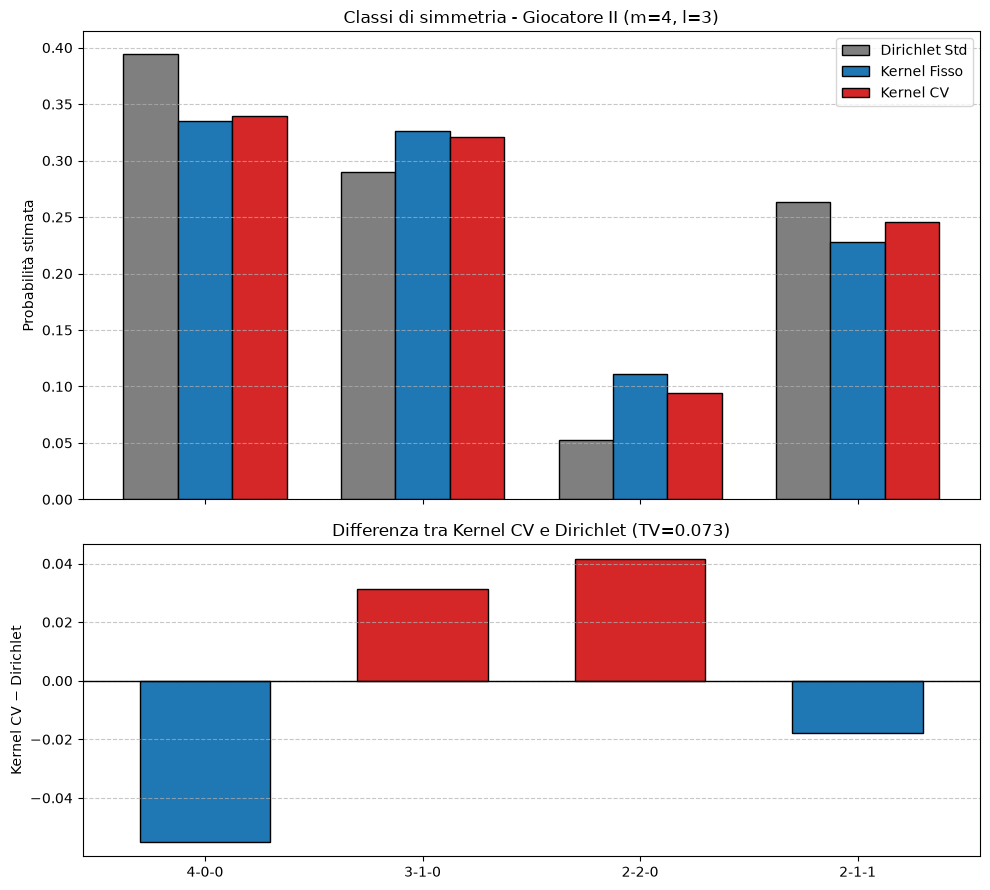

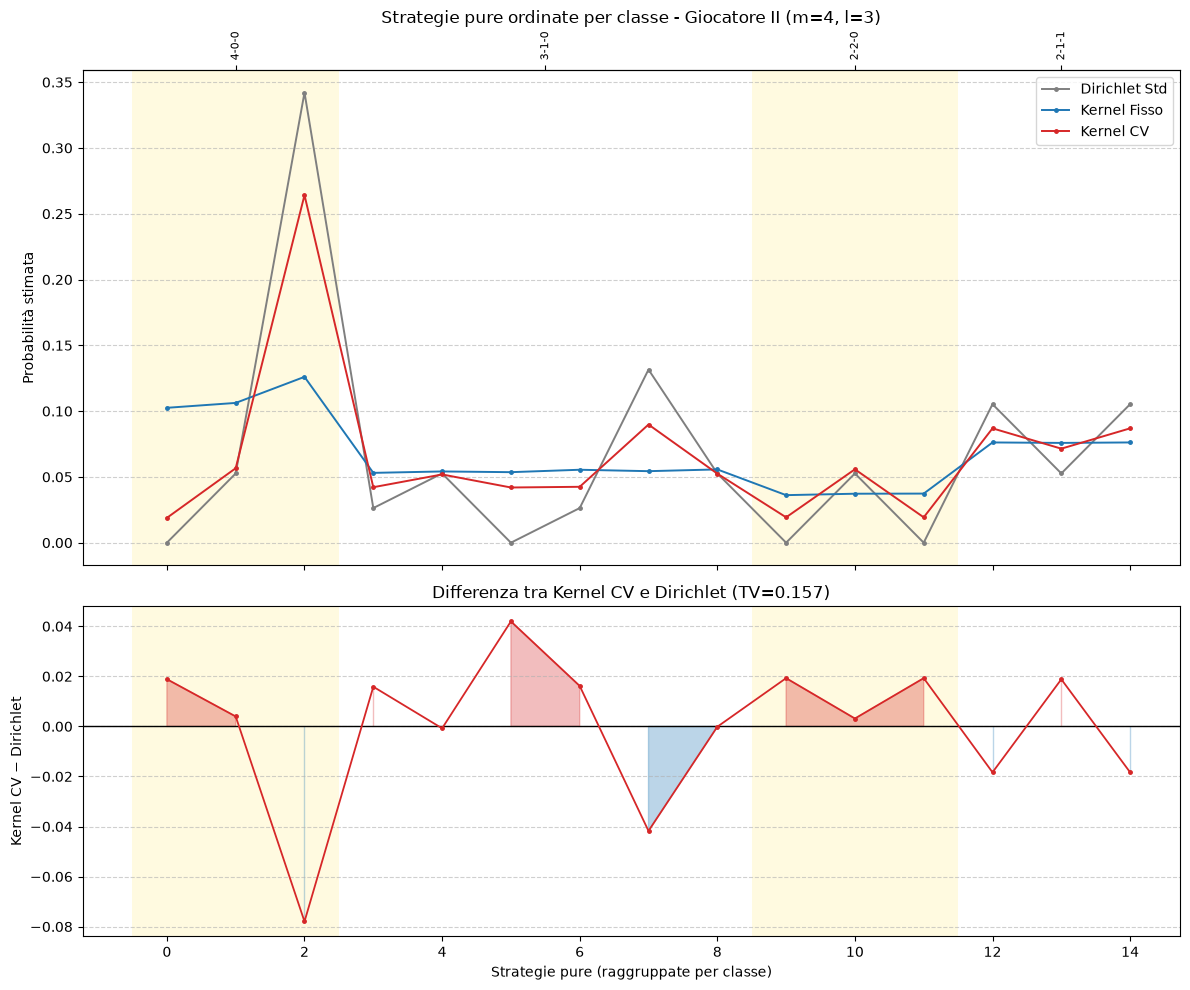

In [19]:
# ==========================================
# 6. VISUALIZZAZIONE
# ==========================================

def tv(p, q):
    """Distanza di variazione totale: 0 = identiche, 1 = disgiunte."""
    return 0.5 * np.sum(np.abs(np.asarray(p) - np.asarray(q)))




modelli = [
    ("Dirichlet Std", prob_dirichlet,    prob_classi_dirichlet, 'tab:gray'),
    ("Kernel Fisso",  prob_kernel_fisso, prob_classi_fisso,     'tab:blue'),
    ("Kernel CV",     prob_kernel_opt,   prob_classi_opt,       'tab:red'),
]

# Differenza Kernel CV - Dirichlet
diff_strat = np.asarray(prob_kernel_opt) - np.asarray(prob_dirichlet)
diff_classi = np.asarray(prob_classi_opt) - np.asarray(prob_classi_dirichlet)



# Differenza Kernel CV - Dirichlet
diff_strat = np.asarray(prob_kernel_opt) - np.asarray(prob_dirichlet)
diff_classi = np.asarray(prob_classi_opt) - np.asarray(prob_classi_dirichlet)

print("\n=== DISTANZA TRA KERNEL CV E DIRICHLET (variazione totale) ===")
print(f"Strategie pure: {tv(prob_kernel_opt, prob_dirichlet):.4f}")
print(f"Classi:         {tv(prob_classi_opt, prob_classi_dirichlet):.4f}")

# ------------------------------------------
# FIGURA 1: CLASSI DI SIMMETRIA
# ------------------------------------------
fig1, (ax, axd) = plt.subplots(
    2, 1, figsize=(max(10, 0.9 * n_classi), 9),
    sharex=True, gridspec_kw={'height_ratios': [3, 2]}
)
x = np.arange(n_classi)
w = 0.25

# Pannello alto: probabilità stimate dai 3 modelli
for k, (nome, ps, pc, col) in enumerate(modelli):
    ax.bar(x + (k - 1) * w, pc, w, color=col, edgecolor='black', label=nome)
ax.set_ylabel("Probabilità stimata")
ax.set_title(f"Classi di simmetria - Giocatore II (m={m}, l={l})")
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Pannello basso: differenza Kernel CV - Dirichlet
colori_diff = ['tab:red' if d >= 0 else 'tab:blue' for d in diff_classi]
axd.bar(x, diff_classi, 0.6, color=colori_diff, edgecolor='black')
axd.axhline(0, color='black', lw=1)
axd.set_ylabel("Kernel CV − Dirichlet")
axd.set_title(f"Differenza tra Kernel CV e Dirichlet "
              f"(TV={tv(prob_classi_opt, prob_classi_dirichlet):.3f})")
axd.set_xticks(x)
axd.set_xticklabels([str(nome) for nome in nomi_classi],
                    rotation=45 if n_classi > 8 else 0,
                    ha='right' if n_classi > 8 else 'center')
axd.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# ------------------------------------------
# FIGURA 2: STRATEGIE PURE (ordinate per classe)
# ------------------------------------------
# Ordine: strategie raggruppate per classe, così si vedono i "blocchi"
mossa_to_index = {mossa: i for i, mossa in enumerate(strategie_giocatore_2)}
ordine = [mossa_to_index[s] for nome in nomi_classi for s in classi_giocatore_2[nome]]
dimensioni = [len(classi_giocatore_2[nome]) for nome in nomi_classi]
bordi = np.concatenate([[0], np.cumsum(dimensioni)])
centri = (bordi[:-1] + bordi[1:]) / 2 - 0.5
xs = np.arange(lunghezza2)

fig2, (axa, axb) = plt.subplots(
    2, 1, figsize=(max(12, 0.12 * lunghezza2 + 6), 10),
    sharex=True, gridspec_kw={'height_ratios': [3, 2]}
)

def evidenzia_classi(a):
    for j in range(n_classi):
        if j % 2 == 0:
            a.axvspan(bordi[j] - 0.5, bordi[j + 1] - 0.5, color='gold', alpha=0.12, lw=0)

# Pannello alto: probabilità stimate dai 3 modelli
evidenzia_classi(axa)
for nome, ps, pc, col in modelli:
    axa.plot(xs, np.asarray(ps)[ordine], color=col, lw=1.4, marker='o', ms=2.5, label=nome)
axa.set_ylabel("Probabilità stimata")
axa.set_title(f"Strategie pure ordinate per classe - Giocatore II (m={m}, l={l})")
axa.legend()
axa.grid(axis='y', linestyle='--', alpha=0.6)

# Etichette delle classi sopra il grafico
ax_top = axa.secondary_xaxis('top')
ax_top.set_xticks(centri)
ax_top.set_xticklabels([str(n) for n in nomi_classi], rotation=90, fontsize=8)

# Pannello basso: differenza Kernel CV - Dirichlet
evidenzia_classi(axb)
axb.axhline(0, color='black', lw=1)
axb.plot(xs, diff_strat[ordine], color='tab:red', lw=1.3, marker='o', ms=2.5)
axb.fill_between(xs, diff_strat[ordine], 0, where=diff_strat[ordine] >= 0,
                 color='tab:red', alpha=0.3)
axb.fill_between(xs, diff_strat[ordine], 0, where=diff_strat[ordine] < 0,
                 color='tab:blue', alpha=0.3)
axb.set_ylabel("Kernel CV − Dirichlet")
axb.set_xlabel("Strategie pure (raggruppate per classe)")
axb.set_title(f"Differenza tra Kernel CV e Dirichlet "
              f"(TV={tv(prob_kernel_opt, prob_dirichlet):.3f})")
axb.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()